# 01 Data generation

Builds two years of hourly historian data for the nitrogen generation unit (NGU) of a fictional fertiliser complex, NitroChem Process Industries Limited, Port Harcourt. The unit supplies purge, blanketing and seal gas N2 to the ammonia and urea plants.

The unit has three cryogenic packages, NGU-A, NGU-B and NGU-C. Each has a feed air compressor, a pre-purification unit (PPU) with molecular sieve adsorbers, a cold box with the main heat exchanger and column, and a turbo-expander. A liquid nitrogen (LIN) tank with vaporisers backs up the header when packages are down.

Data disclaimer: all data here is synthetic. No proprietary or confidential operational data from any employer or facility was used. The full generator is `src/generate_nitrogen_plant_data.py`; run it with the same seed and you get the same numbers.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from plant_style import (apply_style, save, load, PACKAGE_COLOURS, CAUSE_COLOURS, ALERT, INK_2,
                         MODE_NAMES, RAW, PROCESSED, SPLIT_VALID, SPLIT_TEST)

apply_style()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

from generate_nitrogen_plant_data import build, FAILURE_MODES, PACKAGES, COMPANY

SEED = 42
tables = build(SEED)
RAW.mkdir(parents=True, exist_ok=True)
for name, df in tables.items():
    df.to_csv(RAW / f"{name}.csv", index=False)
    print(f"{name:26s} {len(df):>7,d} rows")

hourly_process_data         52,560 rows
hourly_plant_data           17,520 rows
downtime_events                111 rows
process_alarms                 545 rows
operator_log                    17 rows
daily_package_summary        2,190 rows
daily_plant_summary            730 rows
instrument_tags                 54 rows


## What went into the generator

Eight failure modes. Four develop over hours or days and leave a trail in the process data. Four are sudden and give no warning at all: grid power dips, motor relay trips, compressor coupling failures and PPU switching valve failures. That is true to life, and it caps what any predictive model can catch.

In [2]:
pd.DataFrame(FAILURE_MODES).T[["category", "description", "precursor_h", "repair_h"]]

,category,description,precursor_h,repair_h
expander_bearing,Mechanical,"Turbo-expander bearing degradation, trip on hi...","(10, 96)","(14, 40)"
compressor_vibration,Mechanical,Feed air compressor high vibration trip,"(6, 96)","(18, 60)"
ppu_breakthrough,Process,"PPU molecular sieve CO2 breakthrough, product ...","(4, 20)","(16, 40)"
cw_loss,Utility,"Cooling water flow loss to aftercooler, trip o...","(3, 8)","(3, 10)"
coupling_failure,Mechanical,"Compressor coupling failure, sudden","(0, 0)","(24, 72)"
valve_failure,Process,"PPU switching valve failed to stroke, feed air...","(0, 0)","(4, 12)"
motor_trip,Electrical,Compressor motor protection relay trip,"(0, 0)","(2, 8)"
grid_dip,Electrical,"Plant power supply dip, all running packages t...","(0, 0)","(3, 8)"


In [3]:
pd.DataFrame(PACKAGES).T[["tag_no", "trips_per_year", "efficiency_penalty", "fouling_per_year", "turnaround"]]

,tag_no,trips_per_year,efficiency_penalty,fouling_per_year,turnaround
NGU-A,1,8.0,0.0,0.03,2025-01-13
NGU-B,2,8.0,0.01,0.035,2025-04-07
NGU-C,3,12.0,0.055,0.085,2025-07-07


NGU-C is the oldest package. It carries a 5.5% compressor efficiency penalty, its intercooler fouls almost three times faster than NGU-A, and it trips more often. Notebook 03 has to find that from the data alone.

## Checks on the output

In [4]:
hourly = tables["hourly_process_data"]
downtime = tables["downtime_events"]

assert len(hourly) == 3 * 730 * 24
assert not hourly.duplicated(["timestamp", "package_id"]).any()
print(hourly["operating_state"].value_counts())
print()
print("Missing values (historian gaps):", f"{hourly.isna().any(axis=1).mean():.2%} of rows")

operating_state
RUN               49069
DOWN_UNPLANNED     1774
DOWN_PLANNED        930
STARTUP             787
Name: count, dtype: int64

Missing values (historian gaps): 0.27% of rows


Steady running ranges, by tag. These are what an operator would call normal.

In [5]:
tags = tables["instrument_tags"]
run = hourly[(hourly.operating_state == "RUN") & (hourly.package_id == "NGU-A")]
cols = tags.loc[tags.package_id == "NGU-A", "column"].tolist()
ranges = run[cols].quantile([0.05, 0.5, 0.95]).T.round(2)
ranges.columns = ["p5", "median", "p95"]
ranges.insert(0, "tag (NGU-A)", tags.loc[tags.package_id == "NGU-A"].set_index("column")["tag"])
ranges.insert(1, "unit", tags.loc[tags.package_id == "NGU-A"].set_index("column")["unit"])
ranges

,tag (NGU-A),unit,p5,median,p95
feed_air_flow_nm3h,FI-101,Nm3/h,1866.50,1894.20,2022.30
feed_air_discharge_pressure_barg,PI-102,barg,9.45,9.50,9.56
feed_air_discharge_temp_degC,TI-103,degC,35.99,38.78,41.66
feed_air_compressor_power_kw,JI-104,kW,294.80,304.20,323.50
compressor_vibration_mm_s,VI-105,mm/s,2.41,2.67,3.03
cooling_water_supply_temp_degC,TI-106,degC,27.02,29.76,32.53
ppu_outlet_co2_ppm,AI-107,ppm,0.15,0.18,0.23
ppu_outlet_dewpoint_degC,AI-108,degC,-73.13,-71.74,-70.26
coldbox_temp_degC,TI-109,degC,-173.00,-172.50,-171.98
coldbox_dp_kpa,PDI-110,kPa,11.03,11.56,12.25


In [6]:
downtime.groupby(["package_id", "event_type", "cause_category"]).size().unstack(fill_value=0)

cause_category         Electrical  Mechanical  Planned  Process  Utility
package_id event_type                                                   
NGU-A      Planned              0           0       10        0        0
           Unplanned            7           4        0        7        2
NGU-B      Planned              0           0        9        0        0
           Unplanned           11           6        0        7        3
NGU-C      Planned              0           0        8        0        0
           Unplanned            8          21        0        7        1

## Two fault signatures, as an operator would see them on the trend screen

A PPU breakthrough gives hours of warning on CO2 and exchanger pressure drop before O2 goes off spec. An expander bearing failure gives days.

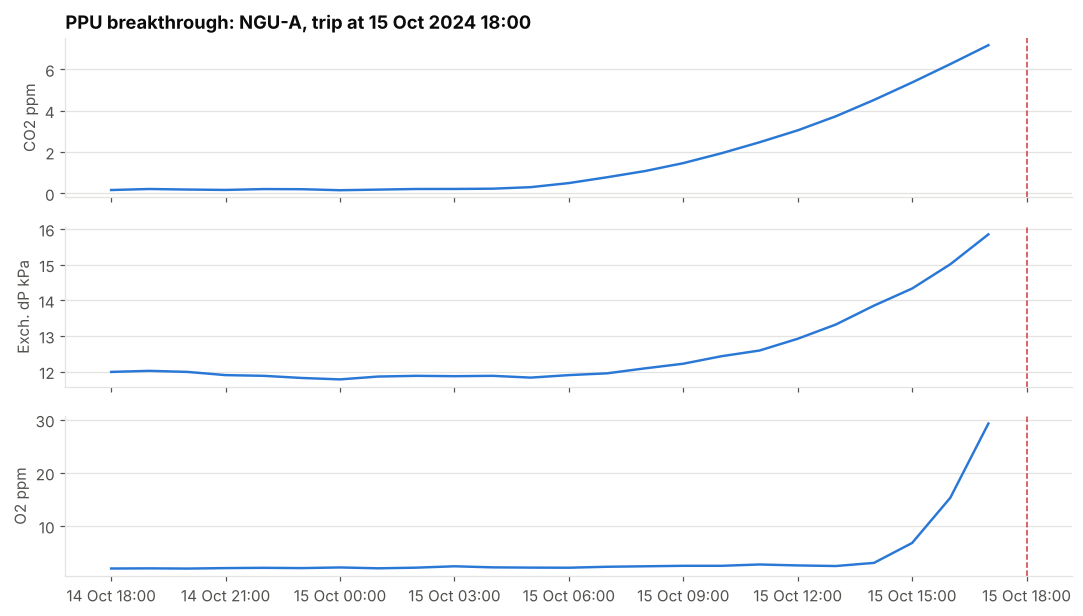

In [7]:
def plot_episode(event, columns, hours_before, title, fname):
    pkg, t = event.package_id, event.trip_time
    w = hourly[(hourly.package_id == pkg) & hourly.timestamp.between(t - pd.Timedelta(hours=hours_before),
                                                                      t + pd.Timedelta(hours=3))]
    fig, axes = plt.subplots(len(columns), 1, figsize=(10, 1.9 * len(columns)), sharex=True)
    for ax, (col, label) in zip(axes, columns.items()):
        ax.plot(w.timestamp, w[col].where(w.operating_state != "DOWN_UNPLANNED"), color=PACKAGE_COLOURS[pkg])
        ax.axvline(t, color=ALERT, lw=1, ls="--")
        ax.set_ylabel(label)
    axes[0].set_title(f"{title}: {pkg}, trip at {t:%d %b %Y %H:%M}")
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
    fig.tight_layout()
    save(fig, fname)
    plt.show()

ppu = downtime[downtime.failure_mode == "ppu_breakthrough"].iloc[0]
plot_episode(ppu, {"ppu_outlet_co2_ppm": "CO2 ppm", "coldbox_dp_kpa": "Exch. dP kPa",
                   "o2_content_ppm": "O2 ppm"}, 24, "PPU breakthrough", "01_ppu_breakthrough_episode")

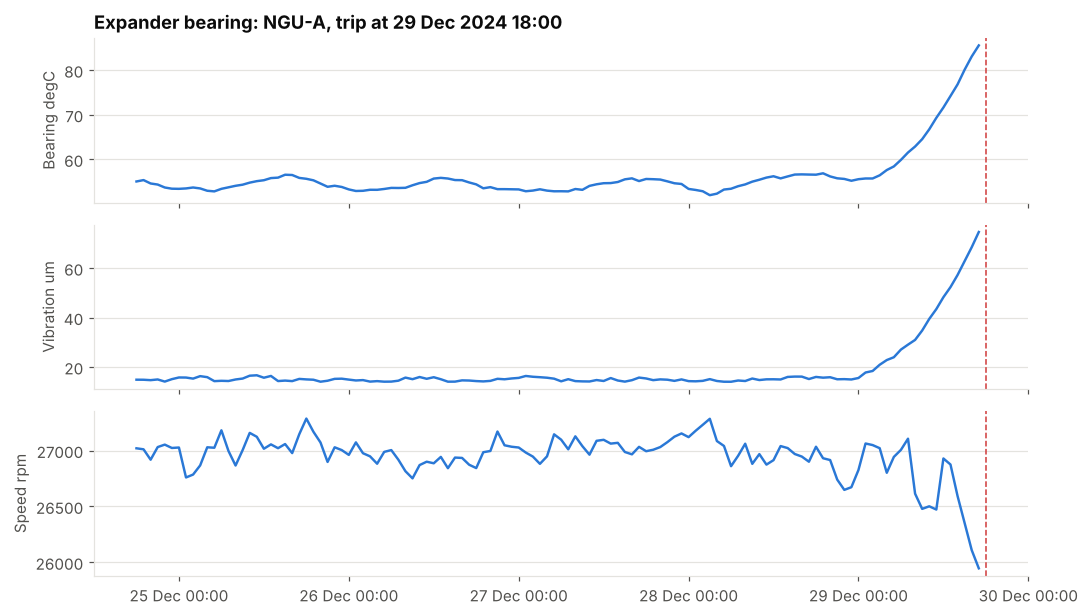

In [8]:
brg = downtime[downtime.failure_mode == "expander_bearing"].iloc[0]
plot_episode(brg, {"expander_bearing_temp_degC": "Bearing degC", "expander_vibration_um": "Vibration um",
                   "expander_speed_rpm": "Speed rpm"}, 120, "Expander bearing", "01_expander_bearing_episode")

## Load to BigQuery (optional)

Set `LOAD_TO_BIGQUERY = True` and fill in your project once you have run `gcloud auth application-default login` on your laptop. The loader replaces each table on every run.

In [9]:
LOAD_TO_BIGQUERY = False
GCP_PROJECT = "your-gcp-project-id"
BQ_DATASET = "nitrochem_ngu"

if LOAD_TO_BIGQUERY:
    from load_to_bigquery import load_folder
    load_folder(RAW, GCP_PROJECT, BQ_DATASET)
else:
    print("Skipped BigQuery load. CSVs are in", RAW.relative_to(RAW.parents[1]))

Skipped BigQuery load. CSVs are in data/raw
